![image](https://www.python.org/static/img/python-logo.png)
# **Inlämningsuppgift 3**

# **Del 1: Planering och grundmeny**
## **Pseudokod**

Presentera menyvalen i terminalen (0–3)

try / except så programmet inte kraschar, samt loop om värdet ligger utanför 0–3
* Be användaren om menyval

* Om val == 1 (Visa):
	Visa listan (om den är tom, meddela användaren)

    Återgå till huvudmenyn
* Om val == 2 (Lägg till):
	Be användaren om ett värde (avsluta med tom inmatning "")

	Kontrollera att värdet inte redan finns (dubblettkontroll)

	Lägg till värdet sist i listan och återgå till huvudmenyn

	Om ”” return menu
* Om val == 3 (Ta bort):

	Kontrollera att listan inte är tom

	Be användaren om vilket värde som ska tas bort (avsluta med "")

    Kontrollera att värdet finns i listan och radera det, annars meddela användaren

	Återgå till huvudmenyn
* Om val == 0 (Avsluta):
 
	Avsluta programmet

## **Flödesschema**

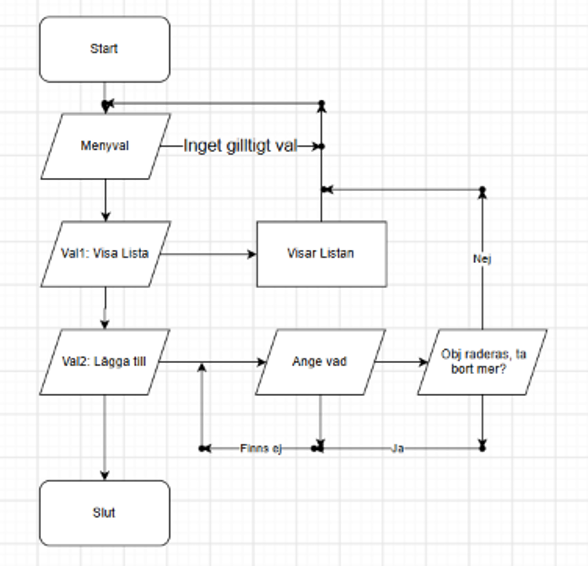


In [1]:
#Mainprogram
print("-=Huvudmenyn=-")
print("0. Avsluta programmet.")
print("1. Visa listan.")
print("2. Lägg till.")
print("3. Ta bort.")
usr_choise = int (input("Ange menyval (0-3): "))


-=Huvudmenyn=-
0. Avsluta programmet.
1. Visa listan.
2. Lägg till.
3. Ta bort.


Ange menyval (0-3):  0


# **Del 2: Använd en lista**

Jag har inte jobbat med Classer på evigheter och vill prova det i Python, så tänkte lägga upp en Todo_list i stil med:

* Städning:

&emsp;&emsp;&emsp;Dammsuga []

&emsp;&emsp;&emsp;Tvätta [✓]
* Handla:

&emsp;&emsp;&emsp; Mjölk []

&emsp; &emsp;&emsp;Kaffe [✓]

där en lista med kattegorier (kaffe och städning) innehåller var sina listor med decioneris av typen item:bool

In [10]:
class Todo_List:
    """
    Handeles a Todo_List with category and sub taks

    Attributes:
        categories (list): List with dictionaries for each category
    """
    
    def __init__(self):
        """Creates a empty list of categories"""
        # The main-list with all categories
        self.categories = []

    def add_category(self, name):
        """Adds a category if it dosn't allready excists.
        Args: 
            name (str): name of category
        """
        # Check if it allready excists
        if self._find_category_(name) is None:
            self.categories.append({
                "category": name,
                "task": {}  # Inner dictionary: {"Task": bool}
            })

    def add_task(self, category_name, task_name):
        """Adds task under under gicen category.
        Args:
            category_name (str): Name of category (adds category if it dosnt excists).
            task_name (str): task that will be added to given category.
        """
        cat = self._find_category_(category_name)
        # if category does not excists, create it
        if cat is None:
            self.add_category(category_name)
            cat = self._find_category_(category_name)
        
        cat["task"][task_name] = False

    def mark_finsished(self, category_name, task_name, task_bool=True):
        """Marks a task as finished (True).

        Args:
            category_name (str): Name of category.
            task_name (str): Name of task.
            task_bool (bool): True if task is finished, if not included True is standard.
            
        Returns:
            bool: True if task was found and and marked, else false
        """
        cat = self._find_category_(category_name)
        if cat and task_name in cat["task"]:
            cat["task"][task_name] = task_bool
            return True
        return False

    def show_all(self):
        """Prints the category and sub tasks lists in the terminal"""
        for cat in self.categories:
            print(f"* {cat['category']}")
            for task, finished in cat["task"].items():
                status = "✓" if finished else " "
                print(f"    [{status}] {task}")

    def _find_category_(self, name):
        """Checks if a category excists

        Args:
            name (str): name of category too look for.

        Returns:
            pointer to the category if it excists, else None
        """
        # Hjälpmetod (understreck = privat i Python, motsvarar private i Java)
        for cat in self.categories:
            if cat["category"].lower() == name.lower():
                return cat
        return None


#Main program
todo = Todo_List()

todo.add_task("Städning", "Dammsuga")
todo.add_task("Städning", "Tvätta")
todo.add_task("Handla", "Mjölk")
todo.add_task("Handla", "Kaffe")

todo.mark_finsished("Handla", "Kaffe")
todo.show_all()

* Städning
    [ ] Dammsuga
    [ ] Tvätta
* Handla
    [ ] Mjölk
    [✓] Kaffe


# **Del 3: Använd funktioner**

Jag har redan löst vissa av deluppgifterna i förra delen, men vill nu lägga till:
* Listorna med tasks sorteras så fördigmarkerade uppgifter hamnar sist under respektive kattegori.
* Ta bort uppgift/kattegori
* funktion som skickar tillbaks alla kategorier som lista samt alla uppgifter för en specifik kattegori


Vi använder följande för att ersätta och sortera uppgifterna under en kattegori

*cat["task"] = dict(*  &emsp;&emsp;&emsp;#Skapar en ny dictionary där vi lagrar dom gamla värderna sorterat

            sorted(cat["task"].items(), key=lambda item: (item[1], item[0].lower())) 
            
        )
        
*cat["task"].items()* &emsp;&emsp;&emsp;#hämtar listan med alla dictoneries för aktuell kattegori

*key=lambda item: (item[1], item[0].lower())* &emsp;&emsp;&emsp;#lambda item tar imot ett element och lagrar det tillfälligt i item och skickar det &emsp;&emsp;&emsp;&emsp;&emsp;&emsp;&emsp;&emsp;&emsp;&emsp;&emsp;&emsp;&emsp;&emsp;&emsp;&emsp;&emsp;&emsp;&emsp;&emsp;&emsp;&emsp;till sorterings algoritmen.

*:(item[1], item[0].lower())*&emsp;&emsp;&emsp; #Talar om i vilken ordning sorterings algoritmen ska sortera efter, i först item[1] dvs *bool* och i &emsp;&emsp;&emsp;&emsp;&emsp;&emsp;&emsp;&emsp;&emsp;&emsp;&emsp;&emsp;&emsp;&emsp;&emsp;andra hand item[0] *uppfigter* men använda liten bokstav vid sortering.

Sen anropar vi funktionen varje gång vi gör en ändring, ett alternativ hade varit att anropa sorteringen vid utskriften istället.

In [13]:
class Todo_List:
    """
    Handeles a Todo_List with category and sub taks

    Attributes:
        categories (list): List with dictionaries for each category
    """
    
    def __init__(self):
        """Creates a empty list of categories"""
        # The main-list with all categories
        self.categories = []

    def add_category(self, name):
        """Adds a category if it dosn't allready excists.
        Args: 
            name (str): name of category
        """
        # Check if it allready excists
        if self._find_category_(name) is None:
            self.categories.append({
                "category": name,
                "task": {}  # Inner dictionary: {"Task": bool}
            })

    def add_task(self, category_name, task_name):
        """Adds task under under gicen category.
        Args:
            category_name (str): Name of category (adds category if it dosnt excists).
            task_name (str): task that will be added to given category.
        """
        cat = self._find_category_(category_name)
        # if category does not excists, create it
        if cat is None:
            self.add_category(category_name)
            cat = self._find_category_(category_name)
        
        cat["task"][task_name] = False
        self._sort_task_(cat) #Saves the lexicon sorted

    def remove_category(self, category_name):
        """Removes a whole category and all its tasks
    
        Returns:
            bool: True if category was found and removed, else False
        """
        cat = self._find_category_(category_name)
        if cat:
            self.categories.remove(cat)
            return True
        return False

    def remove_task(self, category_name, task_name):
        """Removes a specifik task from a category.
    
        Returns:
            bool: True if task was found and removed, else False
        """
        cat = self._find_category_(category_name)
        if cat:
            # Letar upp exakt nyckel oavsett stora/små bokstäver
            for key in list(cat["task"].keys()):
                if key.lower() == task_name.lower():
                    del cat["task"][key]
                    return True
        return False

    def mark_finsished(self, category_name, task_name):
        """changing the value between finished (True) and not finished (False) .

        Args:
            category_name (str): Name of category.
            task_name (str): Name of task.
            
        Returns:
            bool: True if task was found and and marked, else false
        """
        cat = self._find_category_(category_name)
        if cat and task_name in cat["task"]:
            if cat["task"][task_name]:
                cat["task"][task_name] = False
            else:
                cat["task"][task_name] = True
            self._sort_task_(cat) #Sorts the tasks if something changed
            return True
        return False

    def show_all(self):
        """Prints the category and sub tasks lists in the terminal"""
        for cat in self.categories:
            print(f"* {cat['category']}")
            for task, finished in cat["task"].items():
                status = "✓" if finished else " "
                print(f"    [{status}] {task}")

    def _find_category_(self, name):
        """Checks if a category excists

        Args:
            name (str): name of category too look for.

        Returns:
            pointer to the category if it excists, else None
        """
        # Hjälpmetod (understreck = privat i Python, motsvarar private i Java)
        for cat in self.categories:
            if cat["category"].lower() == name.lower():
                return cat
        return None

    def _sort_task_(self, cat):
        """Sort and save tasks: Not finished first (False), marked as done (True) last"""
        cat["task"] = dict(
            sorted(cat["task"].items(), key=lambda item: (item[1], item[0].lower())) 
        )
        
    def get_all_categories(self):
        """Returns a list with all categories
            Retunrs:
                list: with all categories
        """
        return [cat["category"] for cat in self.categories]

    def get_all_tasks(self, category_name):
        """Returns a list with all tasks for a specifik category
            Retunrs:
                list: with all tasks, None if category dosnt excist
        """
        cat = self._find_category_(category_name)
        if cat:
            return list(cat["task"].keys())
        return None



    
#Mainprogram
todo = Todo_List()
todo.add_task("Städning", "Dammsuga")
todo.add_task("Städning", "Tvätta")
todo.add_task("Handla", "Mjölk")
todo.add_task("Handla", "Kaffe")
todo.add_task("Handla", "Bröd")

print("-=Huvudmenyn=-")
print("0. Avsluta programmet.")
print("1. Visa listan.")
print("2. Lägg till.")
print("3. Ta bort.")
usr_choise = int (input("Ange menyval (0-3): "))
if usr_choise == 1:
    todo.show_all()
elif usr_choise == 2:
    todo.show_all()
    print("-=Lägga till menyn=-")
    print("0. Tillbaks.")
    print("1. Ny kattegori.")
    print("2. Uppgift.")
    usr_choise = int (input("Ange menyval (0-2): "))
    if usr_choise == 0:
        pass
    if usr_choise == 1:
        usr_cat = input("Ange Kattegori: ")
        usr_task = input("Ange en uppgift: ")
        todo.add_task(usr_cat.lower().capitalize(), usr_task.lower().capitalize())
    elif usr_choise == 2:
        cat = todo.get_all_categories()
        nr = 1
        for x in cat:
            print(f"{nr}: {x}")
            nr += 1
        print("-=Vilken kattegori=-")
        usr_choise = int (input(f"Ange categori nummer (0-{(len(cat))}): "))
        usr_task = input("Ange en uppgift: ")
        todo.add_task(cat[usr_choise-1], usr_task.lower().capitalize())
elif usr_choise == 3:
    pass
elif usr_choise == 0:
    pass
todo.mark_finsished("Handla", "Kaffe")
todo.mark_finsished("Städning", "Dammsuga")
todo.show_all()

-=Huvudmenyn=-
0. Avsluta programmet.
1. Visa listan.
2. Lägg till.
3. Ta bort.


Ange menyval (0-3):  2


* Städning
    [ ] Dammsuga
    [ ] Tvätta
* Handla
    [ ] Bröd
    [ ] Kaffe
    [ ] Mjölk
-=Lägga till menyn=-
0. Tillbaks.
1. Ny kattegori.
2. Uppgift.


Ange menyval (0-2):  2


1: Städning
2: Handla
-=Vilken kattegori=-


Ange categori nummer (0-2):  2
Ange en uppgift:  0


* Städning
    [ ] Tvätta
    [✓] Dammsuga
* Handla
    [ ] 0
    [ ] Bröd
    [ ] Mjölk
    [✓] Kaffe


# **Del 4: Använd loopar och villkor**


In [4]:
class Todo_List:
    """
    Handeles a Todo_List with category and sub taks

    Attributes:
        categories (list): List with dictionaries for each category
    """
    
    def __init__(self):
        """Creates a empty list of categories"""
        # The main-list with all categories
        self.categories = []

    def add_category(self, name):
        """Adds a category if it dosn't allready excists.
        Args: 
            name (str): name of category
        """
        # Check if it allready excists
        if self._find_category_(name) is None:
            self.categories.append({
                "category": name,
                "task": {}  # Inner dictionary: {"Task": bool}
            })

    def add_task(self, category_name, task_name):
        """Adds task under under gicen category.
        Args:
            category_name (str): Name of category (adds category if it dosnt excists).
            task_name (str): task that will be added to given category.
        """
        cat = self._find_category_(category_name)
        # if category does not excists, create it
        if cat is None:
            self.add_category(category_name)
            cat = self._find_category_(category_name)
        
        cat["task"][task_name] = False
        self._sort_task_(cat) #Saves the lexicon sorted

    def remove_category(self, category_name):
        """Removes a whole category and all its tasks
    
        Returns:
            bool: True if category was found and removed, else False
        """
        cat = self._find_category_(category_name)
        if cat:
            self.categories.remove(cat)
            return True
        return False

    def remove_task(self, category_name, task_name):
        """Removes a specifik task from a category.
    
        Returns:
            bool: True if task was found and removed, else False
        """
        cat = self._find_category_(category_name)
        if cat:
            # Letar upp exakt nyckel oavsett stora/små bokstäver
            for key in list(cat["task"].keys()):
                if key.lower() == task_name.lower():
                    del cat["task"][key]
                    return True
        return False

    def mark_finsished(self, category_name, task_name):
        """changing the value between finished (True) and not finished (False) .

        Args:
            category_name (str): Name of category.
            task_name (str): Name of task.
            
        Returns:
            bool: True if task was found and and marked, else false
        """
        cat = self._find_category_(category_name)
        if cat and task_name in cat["task"]:
            if cat["task"][task_name]:
                cat["task"][task_name] = False
            else:
                cat["task"][task_name] = True
            self._sort_task_(cat) #Sorts the tasks if something changed
            return True
        return False

    def show_all(self):
        """Prints the category and sub tasks lists in the terminal"""
        for cat in self.categories:
            print(f"* {cat['category']}")
            for task, finished in cat["task"].items():
                status = "✓" if finished else " "
                print(f"    [{status}] {task}")

    def _find_category_(self, name):
        """Checks if a category excists

        Args:
            name (str): name of category too look for.

        Returns:
            pointer to the category if it excists, else None
        """
        # Hjälpmetod (undersscore = privat in Python, equal too private in Java)
        for cat in self.categories:
            if cat["category"].lower() == name.lower():
                return cat
        return None

    def _sort_task_(self, cat):
        """Sort and save tasks: Not finished first (False), marked as done (True) last"""
        cat["task"] = dict(
            sorted(cat["task"].items(), key=lambda item: (item[1], item[0].lower())) 
        )
        
    def get_all_categories(self):
        """Returns a list with all categories
            Retunrs:
                list: with all categories
        """
        return [cat["category"] for cat in self.categories]

    def get_all_tasks(self, category_name):
        """Returns a list with all tasks for a specifik category
            Retunrs:
                list: with all tasks, None if category dosnt excist
        """
        cat = self._find_category_(category_name)
        if cat:
            return list(cat["task"].keys())
        return None





def get_user_input(value_range, data_type, header="", list=[]):
    """Handles all user inputs
        Atr:
            Value_range: can be str if data_type is str, else int(range)
            data_type: int or str
            list: Header and menu values, list[0] is header. (optinal)

        Returns:
            data_type: integer or string
    """
    if list:
        nr = 1
        print(header)
        print("0. Tillbaks.")
        for value in list:
            print(f"{nr}. {value}.")
            nr += 1
    while True:
        try:
            if data_type is int:
                usr_choise = data_type (input(f"Ange menyval ({min(value_range)}-{max(value_range)}): "))
                if usr_choise in value_range:
                    return usr_choise
            else:
                usr_choise = input(f"{value_range} + : ").strip() #Ser till att det inte går att mata in enbart mellanslag
                if len(usr_choise) > 0 and usr_choise != " ":
                    return usr_choise
        except Exception as e:
            print(F"Ops något gick fel: {type(e)}, försök igen")
            
        
#Main menu
todo = Todo_List() #Creats a todo instance of todo_List

#Adds som random values to list
todo.add_task("Städning", "Dammsuga")
todo.add_task("Städning", "Tvätta")
todo.add_task("Handla", "Mjölk")
todo.add_task("Handla", "Kaffe")
todo.add_task("Handla", "Bröd")
todo.mark_finsished("Handla", "Kaffe")
todo.mark_finsished("Städning", "Dammsuga")

while True:
    print("\n-=Huvudmenyn=-")
    print("0. Avsluta programmet.")
    print("1. Visa listan.")
    print("2. Lägg till.")       
    print("3. Ta bort.")
    print("4. Markera som färdigt.")
    usr_menu_input = get_user_input(range(0,5), int)
    if usr_menu_input == 0:
        print("Avslutar, tack för denna gången!")
        break
        
    if usr_menu_input == 1: #Show list
        todo.show_all()
        
    elif usr_menu_input == 2: #add item
        usr_nr = get_user_input(range(0,3), int,"-=Alternativ=-", [ "Ny kattegori", "Uppgift"])
        if usr_nr == 0: #Return to main menu
            pass
        elif usr_nr == 1: #Add category
            #Asks user for input and sends all atributs needed to ask the question
            usr_cat = get_user_input("Ange Kattegori: ", str)
            usr_task = get_user_input("Ange en uppgift: ", str)                     
            todo.add_task(usr_cat.lower().capitalize(), usr_task.lower().capitalize())
        elif usr_nr == 2: #add task to ecisting category
            options = todo.get_all_categories()
            if options: #Is there anything in category
                #Asks user for input and sends all atributs needed to ask the question
                usr_input = get_user_input(range(0, len(options)+1), int, "-=Vilken kattegori=-", options)  #returns a index of category
                if usr_input != 0: #Return to main menu
                    #Asks user for input and sends all atributs needed to ask the question
                    usr_task = get_user_input("Ange en uppgift: ", str)
                    todo.add_task(options[usr_input - 1], usr_task.lower().capitalize())
            else: #No category items in list
                #Asks user for input and sends all atributs needed to ask the question
                usr_cat = get_user_input("Ange en kattegori: ", str)
                usr_task = get_user_input("Ange en uppgift: ", str)
                todo.add_task(usr_cat.lower().capitalize(), usr_task.lower().capitalize())
    elif usr_menu_input == 3: #Remove item
        usr_nr = get_user_input(range(0,3), int, "-=Alternativ=-", [ "Radera hel kattegori", "Radera Uppgift"])
        if usr_nr == 1: #Remove category
            options = todo.get_all_categories()
            if options:
                #Asks user for input and sends all atributs needed to ask the question
                usr_input = get_user_input(range(0, len(options) + 1), int, "-=Vilken kattegori ska raderas=-", options)  #returns a index of category
                if todo.remove_category(options[usr_input - 1]):
                    print("Uppgifterna raderades.\n")
                else:
                    print("Något gick fel, inget ändrades.\n")
            else:
                print("Det finns inga värden sparade.\n")
        elif usr_nr == 2: #Remove task
            all_cat = todo.get_all_categories()
            if all_cat:
                #Asks user for input and sends all atributs needed to ask the question
                cat_index = get_user_input(range(0, len(all_cat) + 1), int, "-=Under vilken kattegori?=-", all_cat)  #returns a index of category
                tasks = todo.get_all_tasks(all_cat[cat_index - 1])
                if tasks:    
                    #Asks user for input and sends all atributs needed to ask the question
                    task_index = get_user_input(range(0, len(tasks) + 1), int, "-=Vilken uppgift ska raderas?=-", tasks)  #returns a index of task
                    if todo.remove_task(all_cat[cat_index - 1], tasks[task_index - 1]):
                        print(f"Följande har raderats: {tasks[task_index - 1]}")
                    else:
                        print("Objektet hittades ej, inget raderades.\n")
                else:
                    print("Det finns inga värden sparade.\n")
            else:
                print("Det finns inga värden sparade.\n")
    elif usr_menu_input == 4: #Mark as done
        all_cat = todo.get_all_categories()
        if all_cat:
            #Asks user for input and sends all atributs needed to ask the question
            cat_index = get_user_input(range(0, len(all_cat) + 1), int, "-=Under vilken kattegori?=-", all_cat)  #returns a index of category
            tasks = todo.get_all_tasks(all_cat[cat_index - 1])
            if tasks:
                #Asks user for input and sends all atributs needed to ask the question
                task_index = get_user_input(range(0, len(tasks) + 1), int, "-=För vilken uppgift ska statusen ändras?=-", tasks)  #returns a index of task
                if todo.mark_finsished(all_cat[cat_index - 1], tasks[task_index - 1]):
                    print("Värdet ändrades.\n")
                else:
                    print("Något gick fel, inget ändrades\n.")
            else:
                print("Listan är tom\n")
        else:
            print("Listan är tom\n")


-=Huvudmenyn=-
0. Avsluta programmet.
1. Visa listan.
2. Lägg till.
3. Ta bort.
4. Markera som färdigt.


Ange menyval (0-4):  0


Avslutar, tack för denna gången!


# **Del 5. Gör programmet tydligt**

Ok, är ganska nöjd med classen, men huvudmenyn blev alldeles för rörig. behöver dela upp den i funktioner. Valde att använda en separat klass för user_input för att slippa upprepa all try/catch och inmatningskod. Tänker att jag kör samma princip för respektive undermeny så programmet blir lättare att läsa

In [5]:
class Todo_List:
    """
    Handeles a Todo_List with category and sub taks

    Attributes:
        categories (list): List with dictionaries for each category
    """
    
    def __init__(self):
        """Creates a empty list of categories"""
        # The main-list with all categories
        self.categories = []

    def add_category(self, name):
        """Adds a category if it dosn't allready excists.
        Args: 
            name (str): name of category
        """
        # Check if it allready excists
        if self._find_category_(name) is None:
            self.categories.append({
                "category": name,
                "task": {}  # Inner dictionary: {"Task": bool}
            })

    def add_task(self, category_name, task_name):
        """Adds task under under gicen category.
        Args:
            category_name (str): Name of category (adds category if it dosnt excists).
            task_name (str): task that will be added to given category.
        """
        cat = self._find_category_(category_name)
        # if category does not excists, create it
        if cat is None:
            self.add_category(category_name)
            cat = self._find_category_(category_name)
        
        cat["task"][task_name] = False
        self._sort_task_(cat) #Saves the lexicon sorted

    def remove_category(self, category_name):
        """Removes a whole category and all its tasks
    
        Returns:
            bool: True if category was found and removed, else False
        """
        cat = self._find_category_(category_name)
        if cat:
            self.categories.remove(cat)
            return True
        return False

    def remove_task(self, category_name, task_name):
        """Removes a specifik task from a category.
    
        Returns:
            bool: True if task was found and removed, else False
        """
        cat = self._find_category_(category_name)
        if cat:
            # Letar upp exakt nyckel oavsett stora/små bokstäver
            for key in list(cat["task"].keys()):
                if key.lower() == task_name.lower():
                    del cat["task"][key]
                    return True
        return False

    def mark_finsished(self, category_name, task_name):
        """changing the value between finished (True) and not finished (False) .

        Args:
            category_name (str): Name of category.
            task_name (str): Name of task.
            
        Returns:
            bool: True if task was found and and marked, else false
        """
        cat = self._find_category_(category_name)
        if cat and task_name in cat["task"]:
            if cat["task"][task_name]:
                cat["task"][task_name] = False
            else:
                cat["task"][task_name] = True
            self._sort_task_(cat) #Sorts the tasks if something changed
            return True
        return False

    def show_all(self):
        """Prints the category and sub tasks lists in the terminal"""
        for cat in self.categories:
            print(f"* {cat['category']}")
            for task, finished in cat["task"].items():
                status = "✓" if finished else " "
                print(f"    [{status}] {task}")

    def _find_category_(self, name):
        """Checks if a category excists

        Args:
            name (str): name of category too look for.

        Returns:
            pointer to the category if it excists, else None
        """
        # Hjälpmetod (undersscore = privat in Python, equal too private in Java)
        for cat in self.categories:
            if cat["category"].lower() == name.lower():
                return cat
        return None

    def _sort_task_(self, cat):
        """Sort and save tasks: Not finished first (False), marked as done (True) last"""
        cat["task"] = dict(
            sorted(cat["task"].items(), key=lambda item: (item[1], item[0].lower())) 
        )
        
    def get_all_categories(self):
        """Returns a list with all categories
            Retunrs:
                list: with all categories
        """
        return [cat["category"] for cat in self.categories]

    def get_all_tasks(self, category_name):
        """Returns a list with all tasks for a specifik category
            Retunrs:
                list: with all tasks, None if category dosnt excist
        """
        cat = self._find_category_(category_name)
        if cat:
            return list(cat["task"].keys())
        return None




def get_user_input(value_range, data_type, header="", options=[]):
    """Handles all user inputs
        Atr:
            Value_range: can be str if data_type is str, else int(range)
            data_type: int or str
            header (str): Header for the menu.
            options (list): List of menu options (optional)

        Returns:
            integer or string with user choise
    """
   # Error handler from input.
    if data_type not in (int, str):
        raise TypeError(f"data_type måste vara int eller str, fick: {data_type}")
    if options:
        nr = 1
        print(header)
        print("0. Tillbaks.")
        for value in options:
            print(f"{nr}. {value}.")
            nr += 1
    while True:
        try:
            if data_type is int:
                usr_choise = data_type (input(f"Ange menyval ({min(value_range)}-{max(value_range)}): "))
                if usr_choise in value_range:
                    return usr_choise
            else:
                usr_choise = input(f"{value_range} + : ").strip() #Makes sure you cant enter just spaces
                if len(usr_choise) > 0 and usr_choise != " ":
                    return usr_choise
        except Exception as e:
            print(F"Ops något gick fel: {type(e)}, försök igen")
            

def handle_add_menu():
    """Menu choise 2: Adds category or task."""
    menu_header = "\n-=Alternativ=-"
    menu_options = ["Ny kategori", "Uppgift"]
    choice = get_user_input(range(0, 3), int, menu_header, menu_options)
    if choice == 0:
        return

    if choice == 1:
        add_new_task_option()
    elif choice == 2:
        category_options = todo.get_all_categories()
        if not category_options:
            add_new_task_option()
            return
            
        menu_header = "\n-=Vilken kategori=-"
        cat_idx = get_user_input(range(0, len(category_options) + 1), int, menu_header, category_options)
        if cat_idx == 0:
            return

        task = get_user_input("Ange en uppgift: ", str)
        todo.add_task(category_options[cat_idx - 1], task.strip().capitalize())


def add_new_task_option():
    """Handles the option for adding new category and task."""
    category = get_user_input("Ange kategori: ", str)
    task = get_user_input("Ange en uppgift: ", str)
    todo.add_task(category.strip().capitalize(), task.strip().capitalize())


def handle_remove_menu():
    """Menu choise 3: Remove category or task."""
    menu_header = "\n-=Alternativ=-"
    menu_options = ["Radera hel kategori", "Radera uppgift"]
    choice = get_user_input(range(0, 3), int, menu_header , menu_options )
    if choice == 0: #Return to main menu
        return

    category_list = todo.get_all_categories()
    if not category_list:
        print("\nDet finns inga värden sparade.\n")
        return

    if choice == 1:
        menu_header = "\n-=Vilken kategori ska raderas=-"
        cat_idx = get_user_input(range(0, len(category_list) + 1), int, menu_header , category_list)
        if cat_idx == 0: #Return to main menu
            return

        if todo.remove_category(category_list[cat_idx - 1]):
            print("\nKategorin och dess uppgifter raderades.\n")
        else:
            print("\nNågot gick fel, inget ändrades.\n")

    elif choice == 2:
        menu_header = "\n-=Under vilken kategori?=-"
        cat_idx = get_user_input(range(0, len(category_list) + 1), int, menu_header, category_list)
        if cat_idx == 0: #Return to main menu
            return

        selected_cat = category_list[cat_idx - 1]
        tasks_list = todo.get_all_tasks(selected_cat)
        if not tasks_list:
            print("\nKategorin är tomm.\n")
            return
        menu_header = "\n-=Vilken uppgift ska raderas?=-"
        task_idx = get_user_input(range(0, len(tasks_list) + 1), int, menu_header, tasks_list)
        if task_idx == 0:
            return

        selected_task = tasks_list[task_idx - 1]
        if todo.remove_task(selected_cat, selected_task):
            print(f"Följande har raderats: {selected_task}\n")
        else:
            print("\nObjektet hittades ej, inget raderades.\n")


def handle_mark_done_menu():
    """Menu choise 4: change task completion status."""
    category_list = todo.get_all_categories()
    if not category_list:
        print("\nListan är tom.\n")
        return
        
    menu_header = "\n-=Under vilken kategori?=-"
    cat_idx = get_user_input(range(0, len(category_list) + 1), int, menu_header, category_list)
    if cat_idx == 0:
        return

    selected_cat = category_list[cat_idx - 1]
    tasks_list = todo.get_all_tasks(selected_cat)
    if not tasks_list:
        print("\nListan är tom.\n")
        return

    menu_header = "\n-=För vilken uppgift ska statusen ändras?=-"
    task_idx = get_user_input(range(0, len(tasks_list) + 1), int, menu_header, tasks_list)
    if task_idx == 0:
        return

    if todo.mark_finsished(selected_cat, tasks_list[task_idx - 1]):
        print("\nVärdet ändrades.\n")
    else:
        print("\nNågot gick fel, inget ändrades.\n")



#Main method
todo = Todo_List() #Creats a todo instance of todo_List

#Adds som random values to list
todo.add_task("Städning", "Dammsuga")
todo.add_task("Städning", "Tvätta")
todo.add_task("Handla", "Mjölk")
todo.add_task("Handla", "Kaffe")
todo.add_task("Handla", "Bröd")
todo.mark_finsished("Handla", "Kaffe")
todo.mark_finsished("Städning", "Dammsuga")


while True:
    print("\n-=Huvudmenyn=-")
    print("0. Avsluta programmet.")
    print("1. Visa listan.")
    print("2. Lägg till.")
    print("3. Ta bort.")
    print("4. Markera som färdigt.")

    choice = get_user_input(range(0, 5), int)

    if choice == 0:
        print("\nAvslutar, tack för denna gången!")
        break
    elif choice == 1:
        todo.show_all()
    elif choice == 2:
        handle_add_menu()
    elif choice == 3:
        handle_remove_menu()
    elif choice == 4:
        handle_mark_done_menu()


-=Huvudmenyn=-
0. Avsluta programmet.
1. Visa listan.
2. Lägg till.
3. Ta bort.
4. Markera som färdigt.


Ange menyval (0-4):  1


* Städning
    [ ] Tvätta
    [✓] Dammsuga
* Handla
    [ ] Bröd
    [ ] Mjölk
    [✓] Kaffe

-=Huvudmenyn=-
0. Avsluta programmet.
1. Visa listan.
2. Lägg till.
3. Ta bort.
4. Markera som färdigt.


Ange menyval (0-4):  2



-=Alternativ=-
0. Tillbaks.
1. Ny kategori.
2. Uppgift.


Ange menyval (0-2):  0


... (7 outputs left out)

Ange menyval (0-2):  0



-=Huvudmenyn=-
0. Avsluta programmet.
1. Visa listan.
2. Lägg till.
3. Ta bort.
4. Markera som färdigt.


Ange menyval (0-4):  0



Avslutar, tack för denna gången!


# **Del 6: Hantera fel**
Eftersom det finns en separat funktion som hanterar all inmatning slipper jag jaga inmatningsfel under varje menyval. Gjorde några missar när programmet skrevs, bland annat glömde jag kolla om listan på uppgifter under respektive kattegori var tom vid borttagning samt markering. Vilket resulterade i att index out of bound genererades eftersom en range från 0 till 1 skickades som möjliga alternativ. Men annars accepteras bara heltal innom rätt intervall för menyval. samt strängar hindrar en att mata in tomma värden och enbart mellanslag med .strip().